# Case Study 22 — Personalised Coupons Under a Budget: Predict Conversion, Calibrate, Optimise, Control

**Priority:** ★★★ Must-visit · **Reference:** Case Study 22 — *Meituan Bike: real-time personalised coupon allocation* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Growth / Promotions, Pricing, Finance, Marketing Analytics
**Data:** ⚠️ **SYNTHETIC** (D-22-01). Meituan's data is confidential and no Indian company has published a method. This is a calibrated simulation with a hidden true price-response model.
**Evidence level of the reference:** Strong (company paper with an online A/B test), but **not Indian**. The Indian setting is our adaptation (a subscription priced in ₹).
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs22_coupon_allocation_uplift_budget.ipynb`

## 0. Executive Summary for Business

*(Synthetic customers with a hidden price-response model, built on the documented design of Meituan Bike's coupon system: predict conversion at each price, calibrate, optimise with a Lagrangian budget multiplier, and control the multiplier during the day. Meituan's data and results are not reproduced, and the setting is not Indian. Written after the analysis.)*

- **The question:** at the same average offered price of ₹79, can a conversion model plus a budget optimiser earn more per customer than random coupons, a flat price, a manual rule and the existing group-level allocation?
- **Personalisation beats random and flat pricing, but not by much, and it did not beat the incumbent.** The calibrated, monotone model (LDM-IR) earns **₹10.17 per exposed user against ₹9.84 for random coupons (+3.3%; gain ₹0.32, CI 0.32 to 0.33)** and ₹9.92 for a flat ₹79. The oracle that knows the truth earns ₹11.32 (+15.0%), so the model captures only **22% of the achievable gain**.
- **The new method lost to the incumbent in this simulation.** The 20-group allocation earns ₹10.27, which is **₹0.11 per user (1.0%) more than LDM-IR** (CI -₹0.115 to -₹0.099). A manual rule (heavier riders pay more) is also ahead of LDM-IR by ₹0.03. This differs from Meituan's reported gain over its offline system, and we report it as found.
- **Calibration fixed the shape, not the revenue.** Isotonic calibration removed all non-monotone price curves (5.2% of customers had a rising curve in the raw model, 0% after) and brought PCOC to 0.999. But the raw uncalibrated model earned slightly more (₹10.26 vs ₹10.17).
- **A realistic A/B test cannot see these gaps.** With 80,000 customers per arm, LDM-IR vs the incumbent shows -₹0.20 (CI -₹0.47 to +₹0.06, p = 0.13). The formula says about **985,000 customers per arm** are needed at the true gap; simulated power stays between 3.5% and 12% at 10,000 to 80,000 per arm.
- **The budget needs a controller.** With a fixed multiplier the average price ended **₹77.81, 1.5% below budget, and below budget on 100% of 200 simulated days**. With PID control it ended at ₹79.00 (error 0.006%).
- **Random traffic is essential.** The same pipeline trained on confounded targeting logs gave **₹9.02 per user (8.4% below random)** with every customer sent to ₹99, against ₹10.13 (+2.9%) trained on random traffic of the same size. The difference is ₹1.11 per user (CI 1.10 to 1.12).
- **Money (assumed 2 crore exposed users a month, 10% variable cost):** about **₹4.9 crore a year over random coupons** (range ₹3.4 to ₹7.0 crore), but **-₹1.6 crore a year against the incumbent** (range -₹1.2 to -₹2.3 crore).
- **I recommend:** do not replace the group-level allocation with this model yet. Keep a 20% random-traffic slice, adopt the PID controller now (it fixes budget drift whichever allocator is used), improve the model (price-monotone constraints, uplift forests), and run a properly sized A/B test.

## 1. The Problem in Simple English

A subscription app (bike rides, a quick-commerce membership, a food-delivery pass) can show each visitor a **different price**: the full price or a coupon that lowers it. Deep coupons win more sign-ups but give away revenue. Marketing gives you a **budget**: *on average, the price offered must not fall below ₹79* (equivalently, the total discount is capped).

Two lazy answers exist. Give **everyone the same price** (easy, but ignores that some people would pay full price anyway and others only buy at a discount). Or give **random coupons** that average out to the budget (a useful baseline, wasteful in practice). A smart system should:

1. **Predict** each customer's chance of buying at every coupon level (conversion model).
2. **Check that the predictions are honest** (calibrated and sensible: a deeper discount should never lower the chance of buying).
3. **Choose** the coupon for each customer that maximises expected revenue (price × chance of buying) while the **average price stays at budget**.
4. **Keep control during the day** when traffic differs from the plan.

Leaders and interviewers want to know:
1. How much extra revenue does personalisation add at the **same budget**, and how much of the ideal does a real model capture?
2. Why **calibration** matters when an optimiser uses the numbers, not just a ranking.
3. Why a **random-traffic** experiment is needed to train the model.
4. How big an **A/B test** must be to see a gain of a few per cent.
5. How to **stay on budget** when the day's customers differ from the plan.

## 2. Reference from the Case File

### (a) What Meituan did — *documented*

| Item | Documented fact (from the reference file) |
|---|---|
| Problem | Personalised subscription coupon for each arriving customer; the old offline integer-programming system set coupons a day ahead, could not use same-day information, grouped customers and stored a value per user. The new system must decide in **50 ms** within a marketing budget under uncertain traffic |
| Data | Random-traffic group of about **3 million** user-level entries (20% of traffic, roughly 100 Chinese cities), split 80/20 train/test; **200+** customer, riding-behaviour and transaction features; online test on **3,867,738** random users in two cities (February 2024, about a month) |
| Approach | Predict conversion (CVR) for each coupon level; calibrate so CVR is **non-increasing in price**; relax the integer program with a **Lagrangian dual**; choose the coupon by argmax over the ladder for a multiplier λ; initialise λ offline by **trisection**; a **PID controller** adjusts λ during the day |
| Model and checks | XGBoost with isotonic-regression calibration; **AUC 0.891** (plain and calibrated); **PCOC 0.971 to 0.982** after calibration |
| Reported results (company/author-reported) | City B: price × CVR **2.15 vs 2.09** for the offline IP (authors report a **2.8%** revenue gain per exposed user); City A: CVR **14.49% vs 12.93%** for random; group-level solve **0.28 s vs 83.42 s** for the offline IP; PID kept average price within about **1%** of target versus about **3%** overshoot without control; deployed to more than 100 million users in 110+ cities (May 2024) |
| Not documented | Significance tests (ND in the summary read), the number of price levels, the exact budget, and any Indian method |

**Source:** Dai, Li, Zhu, Lin, Huang, "Data-Driven Real-time Coupon Allocation in the Online Platform", arXiv:2406.05987v3 (17 Jun 2024). Dai, Lin and Huang are at Meituan. Indian practice is probably closer to **uplift modelling**; we found no public Indian method source.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 200,000 random-traffic users (one random coupon each), 80,000 users logged under a **targeting rule** (confounded data), and 240,000 online users for policy evaluation. Price ladder **₹59, 69, 79, 89, 99** (our assumption); 12 features instead of 200+; hidden true price sensitivity per user |
| Calibration to the documented | Mean random-arm conversion ≈ **13%** (documented: 12.93% in one city) |
| Methods compared | Random coupon; one price for all (₹79); a manual rule; **group-level allocation** (our version of the offline IP: customers clustered into 20 groups); **LDM** (conversion model + Lagrangian, no calibration); **LDM-IR** (calibrated and monotone); and an **oracle** that knows the true response |
| Statistics added | Randomisation check; price-response tests; calibration (PCOC, slope, ECE) before and after isotonic regression; an LP check on the Lagrangian; **paired bootstrap** policy comparisons with Holm correction; a **simulated A/B test** and a **power study**; a PID simulation; and a demonstration that **confounded logs** give a worse policy than random traffic |

### (c) How the industry uses this

Personalised discounting under a budget is standard in food delivery, quick commerce, ride hailing and subscriptions: **predict-then-optimise** with a budget multiplier. Indian companies publish very little about it; practice is usually **uplift (incremental) modelling** plus rules, and interviewers ask about calibration, budget constraints and experiment design.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Which coupon should each customer get so that revenue is highest while the average offered price stays at ₹79? |
| Analytical | Can a conversion model trained on random traffic, calibrated and fed to a Lagrangian optimiser, beat random, flat, rule-based and group-level allocation at the same budget, and how would we prove it? |

**Hypotheses**
- **H1 (randomisation):** H0: random coupon assignment is independent of the features (ANOVA / chi-square, Holm).
- **H2 (price response):** H0: conversion does not depend on price; **H2b:** H0: the price effect is the same for all customers (interaction tests).
- **H3 (calibration):** H0: the predicted-to-observed ratio (PCOC) is 1 and the calibration slope is 1; **H3b:** H0: the model's conversion is non-increasing in price for every customer.
- **H4 (policy value):** H0: LDM-IR has the same expected revenue per user as the incumbent group-level allocation at equal budget (paired bootstrap; Holm).
- **H5 (online test):** H0: the A/B revenue per exposed user does not differ between LDM-IR and the incumbent (Welch t-test); we also measure power.
- **H6 (data):** H0: a model trained on confounded targeted logs yields the same policy value as one trained on random traffic.

**Primary metric:** expected **revenue per exposed user** (price × conversion) at the **same average price**. **Secondary:** conversion rate, PCOC, AUC, budget error.

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, sparse
from scipy.optimize import linprog
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.isotonic import IsotonicRegression
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public coupon-response data | **None for India.** The best-known public sets are Criteo Uplift (advertising), Hillstrom (email) and Starbucks promotions. None has a price ladder with a budget, none is Indian and none has a known true response. |
| Meituan's data | Confidential (200+ features, about 3 million users). |
| **Decision** | Synthetic users with a hidden price-response model, so we can score every policy against the truth and still run a realistic A/B simulation (D-22-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs22.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 22 (budget-constrained personalised coupon allocation, Meituan Bike style)
==============================================================================================================
THIS DATA IS SYNTHETIC. The company data (200+ features, ~3 million random-traffic users) is confidential.

Documented context (Dai, Li, Zhu, Lin, Huang, arXiv:2406.05987v3, 2024): subscription coupons for a bike-sharing
platform; a random-traffic group (20% of traffic) is used to train a conversion (CVR) model; the model is calibrated
(isotonic regression, PCOC 0.971-0.982, AUC 0.891); coupons are chosen by a Lagrangian-dual argmax with lambda found by
trisection; a PID controller keeps the average offered price near the budget. Reported random-arm CVR in one city: 12.93%.

Simulation (all numbers below are OUR assumptions, calibrated only to the ~13% random-arm CVR):
  * Price ladder (Rs per month): 59, 69, 79, 89, 99. Offered price = price after the coupon.
  * Each user has 12 observed features and two hidden quantities: baseline purchase propensity a(x) and price
    sensitivity beta(x) (partly explained by the features, partly hidden).
  * True CVR(x, p) = sigmoid(a - beta * (p - 79) / 10). Hidden truth columns are prefixed "_".
  * Three populations:  random_traffic (price drawn uniformly, outcome logged = the training data),
                        logged_policy (price set by a targeting rule that favours high-propensity users: confounded data),
                        online (the population used for policy evaluation and the simulated A/B test; carries an arrival hour).
  * Data-quality defects in random_traffic: duplicate rows, missing features, impossible values, invalid price codes.

Outputs: data/cs22/random_traffic.csv.gz, logged_policy.csv.gz, online_features.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.optimize import brentq

SEED = 42
LADDER = np.array([59.0, 69.0, 79.0, 89.0, 99.0]); P_REF = 79.0
N_RANDOM, N_LOGGED, N_ONLINE = 200_000, 80_000, 240_000
FEATS = ["tenure_days", "rides_last30", "rides_last90", "avg_ride_min", "city_tier", "age", "prev_subscriber",
         "days_since_last_ride", "coupons_redeemed_90d", "sessions_7d", "weekend_share", "spend_90d"]
TARGET_CVR = 0.13


def _sig(z):
    return 1 / (1 + np.exp(-z))


def _population(n, rng, intercept=None):
    e = rng.normal(0, 1, n)                                    # engagement (hidden driver of many features)
    tier = rng.choice([1, 2, 3], n, p=[0.35, 0.40, 0.25])
    sens = -0.45 * e + 0.35 * (tier == 3) - 0.25 * (tier == 1) + rng.normal(0, 0.8, n)   # price sensitivity driver
    lam30 = np.exp(1.5 + 0.55 * e)
    r30 = rng.poisson(lam30); r90 = r30 + rng.poisson(2 * lam30)
    df = pd.DataFrame({
        "tenure_days": np.round(rng.lognormal(5.3, 0.9, n)).astype(int),
        "rides_last30": r30, "rides_last90": r90,
        "avg_ride_min": np.round(rng.lognormal(2.4, 0.35, n), 1),
        "city_tier": tier,
        "age": np.clip(np.round(rng.normal(28, 7, n)), 16, 65).astype(int),
        "prev_subscriber": rng.binomial(1, _sig(-0.7 + 0.55 * e)),
        "days_since_last_ride": np.minimum(90, np.round(rng.exponential(6 * np.exp(-0.5 * e)))).astype(int),
        "coupons_redeemed_90d": rng.poisson(np.exp(-0.2 + 0.45 * sens)),
        "sessions_7d": rng.poisson(np.exp(1.3 + 0.5 * e)),
        "weekend_share": np.round(rng.beta(2, 3, n), 3),
        "spend_90d": np.round(r90 * rng.lognormal(np.log(14), 0.3, n) * (1 + 0.1 * (tier == 1)), 0),
    })
    a_raw = 0.55 * e + 0.45 * df.prev_subscriber - 0.03 * df.days_since_last_ride + 0.12 * np.log1p(df.sessions_7d) + rng.normal(0, 0.45, n)
    beta = 0.20 * np.exp(0.60 * (sens + rng.normal(0, 0.35, n)))   # true price sensitivity (hidden), per Rs 10
    return df, a_raw.values, beta


def _cvr(a, beta, price):
    return _sig(a[:, None] - beta[:, None] * (np.asarray(price)[None, :] - P_REF) / 10)


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    parts = {}
    sizes = {"random": N_RANDOM, "logged": N_LOGGED, "online": N_ONLINE}
    raw = {k: _population(n, rng) for k, n in sizes.items()}
    # intercept so that the mean CVR over the uniform ladder in the random population is TARGET_CVR
    a0, b0 = raw["random"][1], raw["random"][2]
    c = brentq(lambda c: _cvr(a0 + c, b0, LADDER).mean() - TARGET_CVR, -6, 6)
    for k, (df, a, beta) in raw.items():
        a = a + c; df = df.copy(); df["user_id"] = np.arange(len(df)) + {"random": 0, "logged": 10_000_000, "online": 20_000_000}[k]
        P = _cvr(a, beta, LADDER)
        for j, p in enumerate(LADDER): df[f"_cvr_{int(p)}"] = P[:, j]
        df["_a"] = a; df["_beta"] = beta
        parts[k] = df
    # random traffic: uniform coupon, logged outcome
    r = parts["random"]; j = rng.integers(0, 5, len(r)); r["offered_price"] = LADDER[j]; pc = r[[f"_cvr_{int(p)}" for p in LADDER]].values[np.arange(len(r)), j]
    r["converted"] = rng.binomial(1, pc)
    # logged policy: confounded targeting. Higher-propensity users are offered HIGHER prices (fewer coupons for people likely to buy anyway)
    l = parts["logged"]; z = np.argsort(np.argsort(l["_a"].values + rng.normal(0, 0.35, len(l)))) / len(l)
    jl = np.minimum(4, (z * 5).astype(int)); l["offered_price"] = LADDER[jl]; pcl = l[[f"_cvr_{int(p)}" for p in LADDER]].values[np.arange(len(l)), jl]; l["converted"] = rng.binomial(1, pcl)
    # online population: arrival hour with a compositional drift (committers ride in commute hours)
    o = parts["online"]; eng = (o["rides_last30"].values - o["rides_last30"].mean()) / o["rides_last30"].std()
    hours = np.arange(24); base = np.array([1, 1, 1, 1, 1.5, 2.5, 4, 6, 6, 4.5, 3.5, 3.5, 4, 4, 3.5, 3.5, 4.5, 6, 6.5, 5, 4, 3, 2, 1.5]); hour = np.zeros(len(o), int)
    commute = np.isin(hours, [6, 7, 8, 9, 17, 18, 19]); w_c = _sig(1.2 * eng); h_commute = rng.random(len(o)) < w_c * 0.7 + 0.15
    pc_, po_ = base * commute, base * ~commute; pc_ = pc_ / pc_.sum(); po_ = po_ / po_.sum()
    hour = np.where(h_commute, rng.choice(24, len(o), p=pc_), rng.choice(24, len(o), p=po_)); o["arrival_hour"] = hour
    # data-quality defects in random_traffic
    dup = r.sample(n=3000, random_state=seed)
    r = pd.concat([r, dup], ignore_index=True)
    for col, frac in (("avg_ride_min", 0.03), ("spend_90d", 0.02), ("days_since_last_ride", 0.015)):
        r.loc[rng.random(len(r)) < frac, col] = np.nan
    bad = rng.random(len(r)) < 0.001; r.loc[bad, "age"] = rng.choice([0, 3, 118, 150], bad.sum())
    bad = rng.random(len(r)) < 0.0008; r.loc[bad, "rides_last30"] = rng.integers(400, 1500, bad.sum())
    bad = rng.random(len(r)) < 0.0015; r.loc[bad, "spend_90d"] = -r.loc[bad, "spend_90d"].abs()
    bad = rng.random(len(r)) < 0.0012; r.loc[bad, "offered_price"] = 0.0
    parts["random"] = r
    return parts, dict(ladder=LADDER, p_ref=P_REF, intercept_shift=c)


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); out = os.path.join(here, "cs22"); os.makedirs(out, exist_ok=True)
    parts, tp = generate()
    parts["random"].to_csv(os.path.join(out, "random_traffic.csv.gz"), index=False)
    parts["logged"].to_csv(os.path.join(out, "logged_policy.csv.gz"), index=False)
    parts["online"][["user_id", "arrival_hour"] + FEATS].to_csv(os.path.join(out, "online_features.csv.gz"), index=False)
    r = parts["random"]; r = r[r.offered_price > 0]
    print("random CVR", r.converted.mean().round(4), "| by price", r.groupby("offered_price").converted.mean().round(4).to_dict())
    o = parts["online"]; C = o[[f"_cvr_{int(p)}" for p in LADDER]].values; rev = C * LADDER
    print("online mean CVR at uniform ladder", C.mean().round(4), "| revenue per user at uniform random", rev.mean().round(3))
    print("share users whose revenue-max price is 59:", (rev.argmax(1) == 0).mean().round(3), "99:", (rev.argmax(1) == 4).mean().round(3), "| unconstrained avg price", LADDER[rev.argmax(1)].mean().round(2))
    # oracle at avg price >= 79 via Lagrangian bisection
    def alloc(lam): return (rev + lam * LADDER[None, :]).argmax(1)
    lo, hi = 0.0, 1.0
    for _ in range(40):
        mid = (lo + hi) / 2
        if LADDER[alloc(mid)].mean() < 79: lo = mid
        else: hi = mid
    j = alloc(hi); print("oracle lambda", round(hi, 4), "avg price", LADDER[j].mean().round(2), "revenue/user", rev[np.arange(len(o)), j].mean().round(3), "gain vs random", (rev[np.arange(len(o)), j].mean() / rev.mean() - 1).round(4), "CVR", C[np.arange(len(o)), j].mean().round(4))
    print("beta quantiles", np.quantile(o["_beta"], [.05, .25, .5, .75, .95]).round(3))

Overwriting data/generate_cs22.py


In [3]:
os.makedirs("data/cs22", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs22 as gen; importlib.reload(gen)
t0 = time.time(); parts, TP = gen.generate(seed=SEED)
GZ = {"method": "gzip", "compresslevel": 1}
parts["random"].to_csv("data/cs22/random_traffic.csv.gz", index=False, compression=GZ); parts["logged"].to_csv("data/cs22/logged_policy.csv.gz", index=False, compression=GZ)
parts["online"][["user_id", "arrival_hour"] + gen.FEATS].to_csv("data/cs22/online_features.csv.gz", index=False, compression=GZ)
print(f"random traffic {len(parts['random']):,} rows | logged policy {len(parts['logged']):,} | online {len(parts['online']):,} | generated and saved in {time.time() - t0:.0f}s")
parts["random"][["user_id"] + gen.FEATS + ["offered_price", "converted"]].head(4)

random traffic 203,000 rows | logged policy 80,000 | online 240,000 | generated and saved in 126s


,user_id,tenure_days,rides_last30,rides_last90,avg_ride_min,city_tier,age,prev_subscriber,days_since_last_ride,coupons_redeemed_90d,sessions_7d,weekend_share,spend_90d,offered_price,converted
0,0,368,5,13,10.5000,2,27,0,3.0000,1,3,0.4930,NaN,59.0000,0
1,1,267,3,6,12.6000,1,22,0,5.0000,0,0,0.5300,142.0000,79.0000,0
2,2,418,7,15,7.3000,3,16,0,0.0000,2,3,0.4330,192.0000,89.0000,0
3,3,76,6,20,19.4000,2,30,1,2.0000,1,5,0.4320,279.0000,89.0000,0


| Parameter | Value | Basis |
|---|---|---|
| Price ladder | ₹59, 69, 79, 89, 99 per month | Our assumption |
| Budget | Average offered price **at least ₹79** (the mean of the ladder, so a uniform random coupon exactly meets it) | Our assumption |
| True response | CVR = sigmoid(a(x) − β(x)·(price − 79)/10); β median ≈ 0.20 per ₹10, spread across users | Our assumption (hidden truth) |
| Random-arm conversion | ≈ 13% | **Documented** (12.93% in one city) |
| Features | 12 (tenure, rides, recency, tier, previous subscriber, coupon history, sessions, spend …) | Our assumption (documented: 200+) |
| Traffic | Random 200,000; logged-policy 80,000; online 240,000 with an arrival hour | Our assumption (documented: ~3 million random users, 3.87 million online) |
| DQ issues | 3,000 duplicate rows, missing values, impossible ages, rides and spend, invalid price codes | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("user_id", "Customer identifier"), ("tenure_days … spend_90d (12 features)", "Customer, riding, recency, coupon-history and spend features, known before the offer"),
    ("offered_price", "Subscription price shown after the coupon (₹59–99)"), ("converted", "1 if the customer subscribed"),
    ("arrival_hour (online only)", "Hour of day the customer arrives (for the budget-control simulation)"),
    ("_cvr_59 … _cvr_99, _a, _beta", "HIDDEN: true conversion probability at each price, baseline propensity, price sensitivity (the twin only)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs22/data_dictionary.csv", index=False); dd

,field(s),meaning
0,user_id,Customer identifier
1,tenure_days … spend_90d (12 features),"Customer, riding, recency, coupon-history and ..."
2,offered_price,Subscription price shown after the coupon (₹59...
3,converted,1 if the customer subscribed
4,arrival_hour (online only),Hour of day the customer arrives (for the budg...
5,"_cvr_59 … _cvr_99, _a, _beta",HIDDEN: true conversion probability at each pr...


## 5. Data Quality Checks

In [5]:
rt = parts["random"]; LAD = gen.LADDER; FE = gen.FEATS; PC = [f"_cvr_{int(p)}" for p in LAD]
checks = {"duplicate user rows": int(rt.duplicated("user_id").sum()), "invalid price codes (not on the ladder)": int((~rt.offered_price.isin(LAD)).sum()),
          "impossible age (< 16 or > 70)": int(((rt.age < 16) | (rt.age > 70)).sum()), "implausible rides_last30 (> 200)": int((rt.rides_last30 > 200).sum()), "negative spend_90d": int((rt.spend_90d < 0).sum())}
print(pd.Series(checks, name="rows").to_string()); print("\nMissing values:", rt[FE].isna().sum()[lambda s: s > 0].to_dict())
rt = rt.drop_duplicates("user_id"); rt = rt[rt.offered_price.isin(LAD)].copy()
rt.loc[(rt.age < 16) | (rt.age > 70), "age"] = np.nan; rt.loc[rt.rides_last30 > 200, "rides_last30"] = np.nan; rt.loc[rt.spend_90d < 0, "spend_90d"] = np.nan
rt = rt.reset_index(drop=True); print(f"\nClean: {len(rt):,} users | conversion {rt.converted.mean():.2%} | impossible values set to missing (the gradient-boosting model handles missing values natively)")
idx = RNG.permutation(len(rt)); n_te = int(0.2 * len(rt)); te = rt.iloc[idx[:n_te]].reset_index(drop=True); trall = rt.iloc[idx[n_te:]]; n_cal = int(0.25 * len(trall))
cal = trall.iloc[:n_cal].reset_index(drop=True); tr = trall.iloc[n_cal:].reset_index(drop=True)
print(f"Split: model-train {len(tr):,} | calibration {len(cal):,} | test {len(te):,}")

duplicate user rows                        3000
invalid price codes (not on the ladder)     213
impossible age (< 16 or > 70)               197
implausible rides_last30 (> 200)            158
negative spend_90d                          269

Missing values: {'avg_ride_min': 6130, 'days_since_last_ride': 2976, 'spend_90d': 4090}



Clean: 199,791 users | conversion 13.08% | impossible values set to missing (the gradient-boosting model handles missing values natively)


Split: model-train 119,875 | calibration 39,958 | test 39,958


**Observation:** we removed **3,000 duplicate user rows** and **213 rows with price codes not on the ladder**. We set **197 impossible ages, 158 implausible ride counts and 269 negative spend values** to missing, and the model handles missing values natively (6,130 missing ride-length, 2,976 missing recency and 4,090 missing spend values remain). The clean random-traffic data has **199,791 users with a 13.08% conversion rate**, close to the documented 12.93% for random coupons in one Meituan city. It is split into 119,875 for training, 39,958 for calibration and 39,958 for testing.

## 6. Exploratory Data Analysis

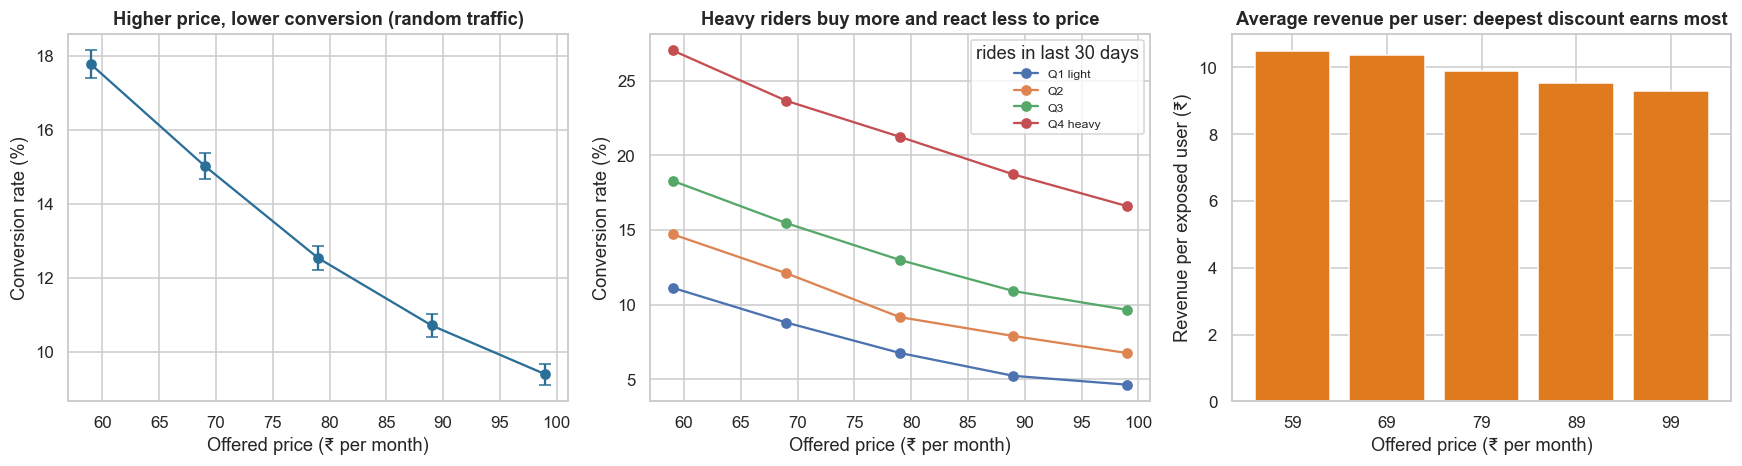

Conversion by price (%): {59.0: 17.77, 69.0: 15.02, 79.0: 12.53, 89.0: 10.71, 99.0: 9.39}
Revenue per user (₹): {59.0: 10.48, 69.0: 10.37, 79.0: 9.9, 89.0: 9.53, 99.0: 9.3}


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
g = rt.groupby("offered_price").converted.agg(["sum", "count"]); ci = np.array([proportion_confint(s, n, method="wilson") for s, n in zip(g["sum"], g["count"])]); m = g["sum"] / g["count"]
axes[0].errorbar(g.index, m * 100, yerr=[(m - ci[:, 0]) * 100, (ci[:, 1] - m) * 100], marker="o", color="#2a6f97", capsize=4); axes[0].set_xlabel("Offered price (₹ per month)"); axes[0].set_ylabel("Conversion rate (%)"); axes[0].set_title("Higher price, lower conversion (random traffic)")
q = pd.qcut(rt.rides_last30.rank(method="first"), 4, labels=["Q1 light", "Q2", "Q3", "Q4 heavy"]); h = rt.assign(q=q).groupby(["q", "offered_price"]).converted.mean().unstack(0) * 100
for c_ in h.columns: axes[1].plot(h.index, h[c_], marker="o", label=str(c_))
axes[1].set_xlabel("Offered price (₹ per month)"); axes[1].set_ylabel("Conversion rate (%)"); axes[1].set_title("Heavy riders buy more and react less to price"); axes[1].legend(title="rides in last 30 days", fontsize=8)
rv = rt.assign(rev=rt.offered_price * rt.converted).groupby("offered_price").rev.mean(); axes[2].bar(rv.index.astype(int).astype(str), rv.values, color="#e07a1f"); axes[2].set_xlabel("Offered price (₹ per month)"); axes[2].set_ylabel("Revenue per exposed user (₹)"); axes[2].set_title("Average revenue per user: deepest discount earns most")
plt.tight_layout(); plt.show()
print("Conversion by price (%):", (m * 100).round(2).to_dict()); print("Revenue per user (₹):", rv.round(2).to_dict())

**Takeaway:** conversion falls steadily with price, from **17.8% at ₹59 to 9.4% at ₹99**. Revenue per exposed user falls much less (₹10.48 at ₹59, **₹9.30 at ₹99**), so on average the deepest discount earns the most: the extra buyers almost pay for the lower price. Heavy riders convert more and react less to price (middle chart), which is the signal a personalised policy tries to use. If everyone reacted the same, one price for all would be as good as any policy.

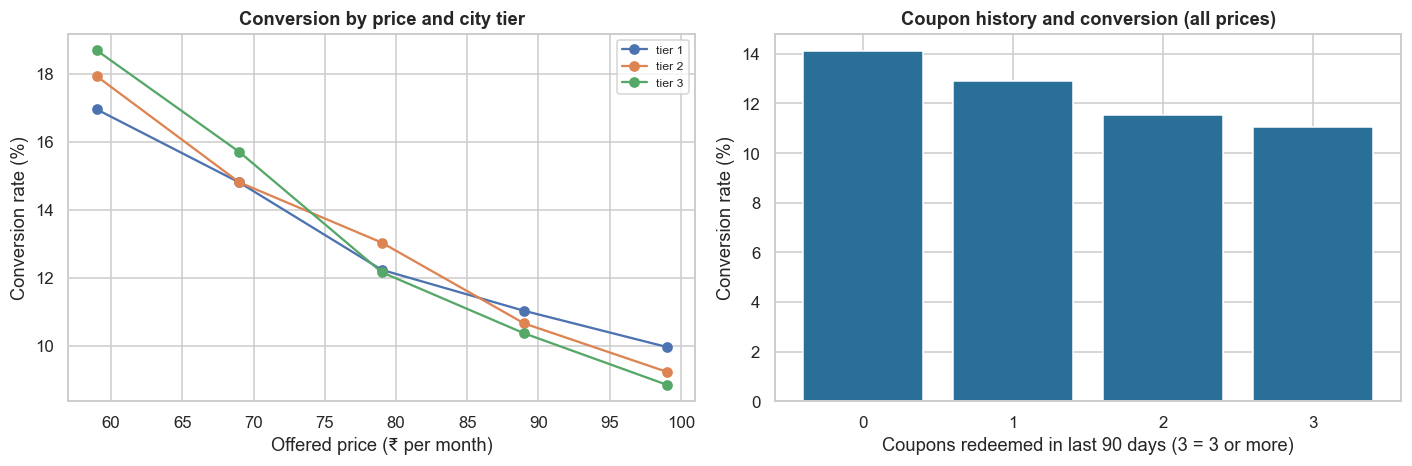

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
tt = rt.groupby(["city_tier", "offered_price"]).converted.mean().unstack(0) * 100
for c_ in tt.columns: axes[0].plot(tt.index, tt[c_], marker="o", label=f"tier {c_}")
axes[0].set_xlabel("Offered price (₹ per month)"); axes[0].set_ylabel("Conversion rate (%)"); axes[0].set_title("Conversion by price and city tier"); axes[0].legend(fontsize=8)
bs = rt.assign(coupon_hist=np.minimum(rt.coupons_redeemed_90d, 3)).groupby("coupon_hist").converted.mean() * 100; axes[1].bar(bs.index.astype(str), bs.values, color="#2a6f97"); axes[1].set_xlabel("Coupons redeemed in last 90 days (3 = 3 or more)"); axes[1].set_ylabel("Conversion rate (%)"); axes[1].set_title("Coupon history and conversion (all prices)")
plt.tight_layout(); plt.show()

**Takeaway:** city tier and coupon history both shift conversion, and the price curves differ across city tiers. These patterns suggest that customers differ in price sensitivity, but the charts do not prove it. Section 7.1 tests it formally, with correction for the number of features tested.

## 7. Statistical Analysis (core section)

### 7.1 Randomisation and the price response

**(a) Why?** The training data is only trustworthy if the coupon was assigned **at random**. We test that, then ask whether price changes conversion and for whom.
- **H1:** H0: features are independent of the assigned price. One-way **ANOVA** for each numeric feature and a **chi-square** for tier and previous subscriber, with **Holm** correction over all 12 tests.
- **H2:** H0: price does not change conversion. **Logistic regression** of conversion on price; **Wald** CI for the effect of ₹10.
- **H2b:** H0: the price effect is the same for all. **Likelihood-ratio** tests of price × feature interactions (one feature at a time, Holm over the features).

#### Code

In [8]:
rows = []
for f in FE:
    if f in ("city_tier", "prev_subscriber"):
        p = stats.chi2_contingency(pd.crosstab(rt[f], rt.offered_price))[1]; rows.append((f, "chi-square", p))
    else:
        d = rt[[f, "offered_price"]].dropna(); p = stats.f_oneway(*[d[f][d.offered_price == v] for v in LAD])[1]; rows.append((f, "ANOVA", p))
bal = pd.DataFrame(rows, columns=["feature", "test", "p"]).set_index("feature"); bal["p_holm"] = multipletests(bal.p, method="holm")[1]
print(f"Balance: smallest raw p = {bal.p.min():.3f}; smallest Holm p = {bal.p_holm.min():.3f}; features with Holm p < 0.05: {(bal.p_holm < 0.05).sum()} of {len(bal)}")
Xp = sm.add_constant(((rt.offered_price - 79) / 10).rename("price10")); lg = sm.Logit(rt.converted, Xp).fit(disp=0); b = lg.params["price10"]; lo_, hi_ = lg.conf_int().loc["price10"]
print(f"Price effect per +₹10: log-odds {b:+.3f} (95% CI {lo_:+.3f} to {hi_:+.3f}), odds ratio {np.exp(b):.3f} (CI {np.exp(lo_):.3f} to {np.exp(hi_):.3f}), p = {lg.pvalues['price10']:.2g}")
base_c = rt.converted.mean(); print(f"Average price elasticity of conversion at ₹79: {b * 7.9 * (1 - base_c):+.2f}")
dnum = rt[["converted", "offered_price"] + FE].copy(); dnum["price10"] = (dnum.offered_price - 79) / 10; ints = []
for f in FE:
    z = dnum[["converted", "price10", f]].dropna(); z[f] = (z[f] - z[f].mean()) / z[f].std()
    m0 = sm.Logit(z.converted, sm.add_constant(z[["price10", f]])).fit(disp=0); z["pf"] = z.price10 * z[f]; m1 = sm.Logit(z.converted, sm.add_constant(z[["price10", f, "pf"]])).fit(disp=0)
    LR = 2 * (m1.llf - m0.llf); ints.append((f, m1.params["pf"], stats.chi2.sf(LR, 1)))
it = pd.DataFrame(ints, columns=["feature", "price × feature log-odds (per SD, per ₹10)", "p"]).set_index("feature"); it["p_holm"] = multipletests(it.p, method="holm")[1]
print(f"Features with a significant price interaction (Holm < 0.05): {list(it.index[it.p_holm < 0.05])}")
it.sort_values("p").round(4)

Balance: smallest raw p = 0.144; smallest Holm p = 1.000; features with Holm p < 0.05: 0 of 12


Price effect per +₹10: log-odds -0.188 (95% CI -0.197 to -0.178), odds ratio 0.829 (CI 0.821 to 0.837), p = 0
Average price elasticity of conversion at ₹79: -1.29


Features with a significant price interaction (Holm < 0.05): ['rides_last30', 'rides_last90', 'city_tier', 'prev_subscriber', 'days_since_last_ride', 'coupons_redeemed_90d', 'sessions_7d', 'spend_90d']


,"price × feature log-odds (per SD, per ₹10)",p,p_holm
feature,,,
coupons_redeemed_90d,-0.0474,0.0000,0.0000
rides_last90,0.0253,0.0000,0.0000
rides_last30,0.0222,0.0000,0.0000
spend_90d,0.0214,0.0000,0.0000
city_tier,-0.0247,0.0000,0.0000
sessions_7d,0.0216,0.0000,0.0000
prev_subscriber,0.0220,0.0000,0.0000
days_since_last_ride,-0.0316,0.0001,0.0005
age,0.0040,0.4028,1.0000


**(c)/(f) Observation:** **(c)** The randomisation looks sound: the smallest raw p-value across the 12 feature balance tests is 0.144 and **none is significant after Holm correction** (0 of 12). **Price clearly matters**: each extra ₹10 lowers the log-odds of converting by 0.188 (95% CI -0.197 to -0.178; odds ratio 0.829, CI 0.821 to 0.837; p is effectively 0), and the average price elasticity at ₹79 is **-1.29**. **Sensitivity differs across customers**: **8 of 12 features have a significant price interaction after Holm correction** (rides in the last 30 and 90 days, city tier, previous subscriber, recency, coupons redeemed, sessions, spend); age, tenure, weekend share and ride length do not. The strongest is coupons redeemed in the last 90 days (-0.047 per SD per ₹10): coupon-heavy customers react more to price. **(f)** The interaction effects are small (0.02 to 0.05 log-odds per SD), so the room for personalisation is modest, which matches the small gains seen later.

### 7.2 The conversion model: accuracy, calibration, monotonicity

**(a) Why?** The optimiser multiplies a **probability** by a price, so a model that ranks well but is mis-scaled gives wrong revenue estimates. We compare a **logistic regression** (one price slope for everyone) with a **gradient-boosting** model (price as a feature, so it can learn who is price-sensitive), then test calibration.
- **H3:** H0: PCOC (sum of predicted ÷ sum of observed conversions) = 1 and the **calibration slope** (logistic regression of the outcome on the model's log-odds) = 1. **Bootstrap CIs** (300 resamples).
- **H3b:** H0: each customer's predicted conversion is non-increasing in price. We count customers whose predictions **violate** it.
- Calibration is fitted on a separate **calibration set** with **isotonic regression**; a **min-max (PAVA) step** then makes each customer's curve non-increasing in price.
- Fitted settings are fixed defaults (no tuning).

#### Code

PAVA check vs scikit-learn: max abs difference 2.220446049250313e-16


model fitted in 183s


model       logistic (one price slope)  gradient boosting, raw  gradient boosting + isotonic
AUC                             0.6950                  0.6954                        0.6944
AUC lo                          0.6864                  0.6876                        0.6875
AUC hi                          0.7034                  0.7042                        0.7010
log loss                        0.3629                  0.3623                        0.3633
Brier                           0.1081                  0.1080                        0.1081
PCOC                            0.9861                  0.9847                        0.9988
PCOC lo                         0.9616                  0.9599                        0.9753
PCOC hi                         1.0094                  1.0079                        1.0237
cal. slope                      0.9927                  0.9946                        0.9262
slope lo                        0.9500                  0.9552        


Customers whose predicted conversion RISES with price somewhere on the ladder: raw 5.2% | calibrated + monotone 0.0%


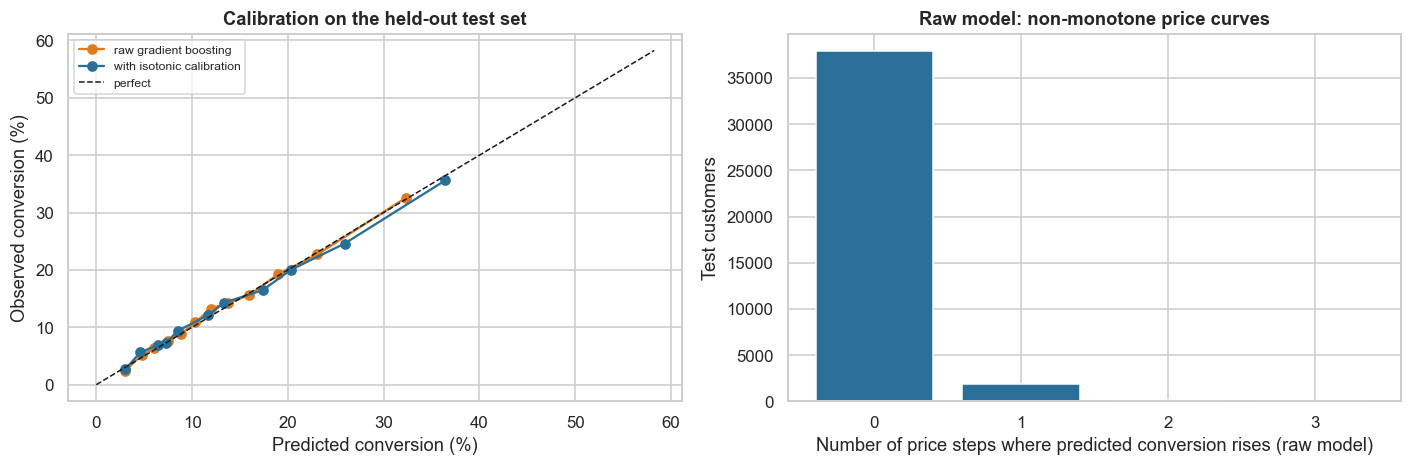

In [9]:
def ladder_pred(model, X):
    out = np.zeros((len(X), len(LAD)))
    for j, p in enumerate(LAD):
        Z = X[FE].copy(); Z["offered_price"] = p; out[:, j] = model.predict_proba(Z[FE + ["offered_price"]])[:, 1]
    return out
def mono_dec(P):
    """Closest non-increasing curve across the price ladder (PAVA via the min-max formula), vectorised over customers."""
    Y = -np.asarray(P, float); n = Y.shape[1]; cs = np.concatenate([np.zeros((len(Y), 1)), np.cumsum(Y, 1)], 1); out = np.empty_like(Y)
    for k in range(n):
        best = None
        for i in range(k + 1):
            mm = np.min([(cs[:, j + 1] - cs[:, i]) / (j - i + 1) for j in range(k, n)], axis=0); best = mm if best is None else np.maximum(best, mm)
        out[:, k] = best
    return -out
def fit_cvr(train, cal_df, seed=SEED):
    m = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=200, early_stopping=True, random_state=seed).fit(train[FE + ["offered_price"]], train.converted)
    p_cal = m.predict_proba(cal_df[FE + ["offered_price"]])[:, 1]; iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p_cal, cal_df.converted); return m, iso
def calibrated_ladder(m, iso, X):
    P = ladder_pred(m, X); return mono_dec(iso.predict(P.ravel()).reshape(P.shape))
# verify the vectorised monotone step against scikit-learn on a sample of random rows
chk = RNG.random((300, 5)); ref = np.array([IsotonicRegression(increasing=False).fit_transform(np.arange(5), r) for r in chk]); print("PAVA check vs scikit-learn: max abs difference", float(np.abs(mono_dec(chk) - ref).max()))
t0 = time.time(); gb, iso = fit_cvr(tr, cal); print(f"model fitted in {time.time() - t0:.0f}s")
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)).fit(tr[["offered_price"]].assign(**{f: tr[f].fillna(tr[f].median()) for f in FE}), tr.converted)
Xte = te[FE + ["offered_price"]]; y = te.converted.values
p_lr = lr.predict_proba(te[["offered_price"]].assign(**{f: te[f].fillna(tr[f].median()) for f in FE}))[:, 1]; p_gb = gb.predict_proba(Xte)[:, 1]; p_ir = iso.predict(p_gb)
def calib_stats(p, y):
    p = np.clip(p, 1e-6, 1 - 1e-6); z = np.log(p / (1 - p)); f = sm.Logit(y, sm.add_constant(z)).fit(disp=0); return p.sum() / y.sum(), f.params[1], f.params[0]
def ece(p, y, bins=10):
    q = pd.qcut(p, bins, duplicates="drop"); g = pd.DataFrame({"p": p, "y": y, "q": q}).groupby("q"); return float((g.size() / len(p) * (g.p.mean() - g.y.mean()).abs()).sum())
rows = []
for name, p in (("logistic (one price slope)", p_lr), ("gradient boosting, raw", p_gb), ("gradient boosting + isotonic", p_ir)):
    pc, sl, ic = calib_stats(p, y); boot = [calib_stats(p[i], y[i]) for i in (RNG.integers(0, len(y), len(y)) for _ in range(300))]; bpc = np.percentile([b_[0] for b_ in boot], [2.5, 97.5]); bsl = np.percentile([b_[1] for b_ in boot], [2.5, 97.5])
    aucs = [roc_auc_score(y[i], p[i]) for i in (RNG.integers(0, len(y), len(y)) for _ in range(200))]
    rows.append((name, roc_auc_score(y, p), *np.percentile(aucs, [2.5, 97.5]), log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)), brier_score_loss(y, p), pc, *bpc, sl, *bsl, ece(p, y)))
cm = pd.DataFrame(rows, columns=["model", "AUC", "AUC lo", "AUC hi", "log loss", "Brier", "PCOC", "PCOC lo", "PCOC hi", "cal. slope", "slope lo", "slope hi", "ECE"]).set_index("model"); print(cm.round(4).T.to_string())
print("\nPCOC by offered price (raw GB vs isotonic):"); pp = pd.DataFrame({"price": te.offered_price, "raw": p_gb, "iso": p_ir, "obs": y}).groupby("price").sum(); print(pd.DataFrame({"raw GB": pp.raw / pp.obs, "isotonic": pp.iso / pp.obs}).round(3).T.to_string())
Pte_raw = ladder_pred(gb, te); viol_raw = ((np.diff(Pte_raw, axis=1) > 1e-9).any(1)).mean(); Pte_cal = calibrated_ladder(gb, iso, te); viol_cal = ((np.diff(Pte_cal, axis=1) > 1e-9).any(1)).mean()
print(f"\nCustomers whose predicted conversion RISES with price somewhere on the ladder: raw {viol_raw:.1%} | calibrated + monotone {viol_cal:.1%}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for name, p, c_ in (("raw gradient boosting", p_gb, "#e07a1f"), ("with isotonic calibration", p_ir, "#2a6f97")):
    q = pd.qcut(p, 12, duplicates="drop"); gg = pd.DataFrame({"p": p, "y": y, "q": q}).groupby("q"); axes[0].plot(gg.p.mean() * 100, gg.y.mean() * 100, marker="o", label=name, color=c_)
mx = max(p_gb.max(), 0.5) * 100; axes[0].plot([0, mx], [0, mx], "k--", lw=1, label="perfect"); axes[0].set_xlabel("Predicted conversion (%)"); axes[0].set_ylabel("Observed conversion (%)"); axes[0].set_title("Calibration on the held-out test set"); axes[0].legend(fontsize=8)
vv = (np.diff(Pte_raw, axis=1) > 1e-9).sum(1); axes[1].bar(pd.Series(vv).value_counts().sort_index().index.astype(str), pd.Series(vv).value_counts().sort_index().values, color="#2a6f97"); axes[1].set_xlabel("Number of price steps where predicted conversion rises (raw model)"); axes[1].set_ylabel("Test customers"); axes[1].set_title("Raw model: non-monotone price curves")
plt.tight_layout(); plt.show()

**Takeaway:** **(c)** Accuracy is modest: **AUC 0.695** for the logistic model and for the raw gradient-boosting model (CI 0.688 to 0.704), and 0.694 after isotonic calibration. Meituan reports 0.891 with over 200 real features; ours has 12 simulated ones and is not comparable. Raw calibration is already good (PCOC 0.985, CI 0.960 to 1.008; slope 0.995). After isotonic calibration PCOC is **0.999** (CI 0.975 to 1.024) but the slope falls to **0.926** (CI 0.883 to 0.969) and ECE rises from 0.0041 to 0.0071, so calibration over-corrected slightly. By price, PCOC is 0.94 at ₹59 raw and 0.96 isotonic. The monotonicity problem is real: **5.2% of customers had a predicted conversion that rises with price somewhere on the ladder in the raw model, and 0% after calibration**. **(f)** Calibration fixes the shape the optimiser needs but is not free: it did not improve probability quality in this run.

### 7.3 The optimiser: Lagrangian dual, trisection, and an LP cross-check

**(a) Why?** The allocation problem is: choose a price for each customer to **maximise Σ price × conversion** subject to **average price ≥ budget**. Relaxing the budget with a multiplier **λ ≥ 0** gives, for each customer, "pick the price that maximises revenue + λ × price", and the **dual function** is convex in λ, so **trisection** finds the best λ. A linear program (LP) on a sample gives the exact optimum of the relaxed problem, so we can measure the **duality gap**.
- **H:** H0: the Lagrangian solution reaches the LP optimum (gap = 0 within rounding).
- We also time the **user-level** solve against a **group-level** solve (our stand-in for the old offline IP), as the paper reports 0.28 s vs 83 s.

#### Code

LP optimum 11.1864 ₹/user | Lagrangian (trisection) 11.1954 ₹/user at lambda 0.0383, average price 78.76 | relative gap -8.10e-04
Solve time on 3,000 customers: trisection 148 ms, LP 1553 ms


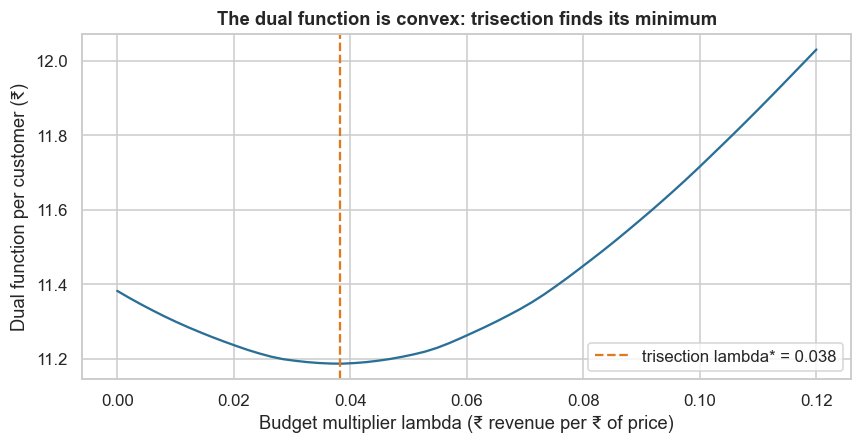

In [10]:
BUDGET = 79.0
def dual(lam, rev, w, B=BUDGET): return float((w * (rev + lam * LAD[None, :]).max(1)).sum() - lam * B * w.sum())
def trisect(rev, w=None, B=BUDGET, hi=2.0, it=45):
    w = np.ones(len(rev)) if w is None else w; lo = 0.0
    for _ in range(it):
        m1, m2 = lo + (hi - lo) / 3, hi - (hi - lo) / 3; d1, d2 = dual(m1, rev, w, B), dual(m2, rev, w, B)
        if d1 < d2: hi = m2
        else: lo = m1
    return (lo + hi) / 2
def avg_price(j, w=None): return float(np.average(LAD[j], weights=w))
def allocate(rev, w=None, B=BUDGET):
    """Lagrangian allocation made budget-feasible: smallest lambda >= lambda* whose average price is at least the budget."""
    w = np.ones(len(rev)) if w is None else w; lam = trisect(rev, w, B); j = (rev + lam * LAD[None, :]).argmax(1)
    if avg_price(j, w) < B - 1e-9:
        lo, hi = lam, 2.0
        for _ in range(60):
            mid = (lo + hi) / 2
            if avg_price((rev + mid * LAD[None, :]).argmax(1), w) < B - 1e-9: lo = mid
            else: hi = mid
        lam = hi; j = (rev + lam * LAD[None, :]).argmax(1)
    return lam, j
on = parts["online"].reset_index(drop=True); TCV = on[PC].values; TREV = TCV * LAD[None, :]; N_ON = len(on)
# LP cross-check on a sample of customers, using calibrated model predictions
sub = on.iloc[RNG.choice(N_ON, 3000, replace=False)].reset_index(drop=True); Rsub = calibrated_ladder(gb, iso, sub) * LAD[None, :]; n = len(sub)
t0 = time.time(); lam_s = trisect(Rsub); t_tri = time.time() - t0; j_s = (Rsub + lam_s * LAD[None, :]).argmax(1)
A_eq = sparse.kron(sparse.eye(n), np.ones((1, len(LAD)))); A_ub = -np.tile(LAD, n)[None, :]
t0 = time.time(); lp = linprog(-Rsub.ravel(), A_ub=A_ub, b_ub=[-BUDGET * n], A_eq=A_eq, b_eq=np.ones(n), bounds=(0, 1), method="highs"); t_lp = time.time() - t0
lp_val = -lp.fun / n; lag_val = Rsub[np.arange(n), j_s].mean(); print(f"LP optimum {lp_val:.4f} ₹/user | Lagrangian (trisection) {lag_val:.4f} ₹/user at lambda {lam_s:.4f}, average price {LAD[j_s].mean():.2f} | relative gap {(lp_val - lag_val) / lp_val:.2e}")
print(f"Solve time on 3,000 customers: trisection {t_tri * 1000:.0f} ms, LP {t_lp * 1000:.0f} ms")
lams = np.linspace(0, 0.12, 60); dv = [dual(l_, Rsub, np.ones(n)) for l_ in lams]
fig, ax = plt.subplots(figsize=(8, 4.2)); ax.plot(lams, np.array(dv) / n, color="#2a6f97"); ax.axvline(lam_s, color="#e07a1f", ls="--", label=f"trisection lambda* = {lam_s:.3f}"); ax.set_xlabel("Budget multiplier lambda (₹ revenue per ₹ of price)"); ax.set_ylabel("Dual function per customer (₹)"); ax.set_title("The dual function is convex: trisection finds its minimum"); ax.legend()
plt.tight_layout(); plt.show()

**Takeaway:** the Lagrangian solution gets within **0.08% of the exact linear-programming optimum** (₹11.195 vs ₹11.186 per customer; the Lagrangian figure is marginally higher because it ends at an average price of ₹78.76, just under the ₹79 budget). The dual function is convex and trisection finds its minimum at lambda 0.038. On 3,000 customers, trisection takes **148 ms against 1,553 ms for the LP**, about 10 times faster, and the gap should widen with size. This supports the Lagrangian method for real-time use.

#### Group-level solve vs user-level solve (runtime)

In [11]:
sc_ = StandardScaler().fit(tr[FE].fillna(tr[FE].median())); Ztr = sc_.transform(tr[FE].fillna(tr[FE].median())); km = KMeans(20, n_init=3, random_state=SEED).fit(Ztr)
tr_g = km.predict(Ztr); gc = pd.DataFrame({"g": tr_g, "p": tr.offered_price.values, "y": tr.converted.values}).groupby(["g", "p"]).y.agg(["mean", "count"]); GC = gc["mean"].unstack(1).reindex(columns=LAD).values; GREV = GC * LAD[None, :]
on_g = km.predict(sc_.transform(on[FE].fillna(tr[FE].median()))); wg = np.bincount(on_g, minlength=20).astype(float)
t0 = time.time(); lam_g, jg = allocate(GREV, wg); t_group = time.time() - t0
print(f"Group-level allocation (20 groups): lambda {lam_g:.4f}, average price {avg_price(jg, wg):.2f}, solve {t_group * 1000:.1f} ms | smallest cell in the group×price table has {int(gc['count'].min())} customers")
t0 = time.time(); Pon_cal = calibrated_ladder(gb, iso, on); t_pred = time.time() - t0; Pon_raw = ladder_pred(gb, on); RCAL = Pon_cal * LAD[None, :]; RRAW = Pon_raw * LAD[None, :]
t0 = time.time(); lam_u, ju = allocate(RCAL); t_user = time.time() - t0
print(f"User-level allocation ({N_ON:,} customers): lambda {lam_u:.4f}, average price {avg_price(ju):.2f}, solve {t_user:.2f} s (model scoring of the ladder: {t_pred:.1f} s)")
pd.DataFrame({"group size (online users)": wg.astype(int), "price chosen": LAD[jg]}).T.round(0)

Group-level allocation (20 groups): lambda 0.0436, average price 79.62, solve 6.5 ms | smallest cell in the group×price table has 99 customers


User-level allocation (240,000 customers): lambda 0.0383, average price 79.46, solve 6.96 s (model scoring of the ladder: 8.7 s)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
group size (online users),"9,933.0000","18,561.0000","19,344.0000","14,451.0000","16,667.0000","9,275.0000","11,451.0000","12,270.0000","12,274.0000","1,230.0000","20,949.0000","4,079.0000","2,915.0000","11,266.0000","8,415.0000","11,995.0000","11,601.0000","18,189.0000","12,171.0000","12,964.0000"
price chosen,99.0000,79.0000,79.0000,99.0000,69.0000,59.0000,89.0000,59.0000,89.0000,99.0000,69.0000,99.0000,99.0000,89.0000,69.0000,99.0000,99.0000,69.0000,69.0000,69.0000


**Observation:** the **group-level allocation is cheap but coarse**: 20 groups solve in **6.5 ms** and choose prices from ₹59 to ₹99 by group, with every group-by-price cell holding at least 99 customers. The **user-level allocation for 240,000 customers solves in 6.96 seconds** (plus 8.7 seconds to score the ladder). We did not reproduce Meituan's 0.28 s vs 83 s comparison because our group-level version is a stand-in, not their integer program. Both are fast enough here; the real question is whether per-customer detail pays, which Section 7.4 answers.

### 7.4 Policy comparison at the same budget (twin truth, paired)

**(a) Why?** Offline accuracy is not the goal; **revenue at the budget** is. In the twin we know every customer's true conversion at every price, so each policy can be scored **exactly** on the 240,000 online users. Policies:

| # | Policy | Rule |
|---|---|---|
| 1 | Random coupon | Each customer gets a uniformly random price (expected value computed exactly) |
| 2 | Flat ₹79 | Everyone sees the budget price |
| 3 | Manual rule | Heavier riders (by last-30-day rides, in quintiles) pay more: ₹59 to ₹99 |
| 4 | Group-level allocation | The 20-group allocation from 7.3 (our incumbent offline IP) |
| 5 | LDM | Raw gradient-boosting predictions + Lagrangian |
| 6 | **LDM-IR** | Calibrated, monotone predictions + Lagrangian |
| 7 | Oracle | True conversion + Lagrangian (the ceiling) |

- **H4:** H0: LDM-IR and the group-level incumbent earn the same revenue per user. **Paired bootstrap** of the per-user difference (500 resamples) and a **paired t-test**; **Holm** over the comparisons of LDM-IR with each other policy.

#### Code

Budget is an average offered price of at least ₹79.

                                                avg price (₹)  conversion (%)  revenue / user (₹)  gain vs random  CI low  CI high  share of oracle gain
policy                                                                                                                                                  
1 random coupon                                       79.0000         13.0070              9.8423          0.0000  0.0000   0.0000                0.0000
2 flat ₹79                                            79.0000         12.5544              9.9180          0.0077  0.0075   0.0078                0.0511
3 manual rule (heavier riders pay more)               78.9999         12.5381             10.2005          0.0364  0.0356   0.0372                0.2418
4 group-level allocation (offline IP stand-in)        79.6231         12.8483             10.2739          0.0439  0.0431   0.0446                0.2913
5 LDM (raw model)            


                                                Δ revenue/user (₹), LDM-IR − other  CI low  CI high  paired t p  p_holm  relative
vs policy                                                                                                                        
1 random coupon                                                             0.3242  0.3177   0.3309      0.0000  0.0000    0.0329
2 flat ₹79                                                                  0.2484  0.2405   0.2565      0.0000  0.0000    0.0251
3 manual rule (heavier riders pay more)                                    -0.0341 -0.0420  -0.0251      0.0000  0.0000   -0.0033
4 group-level allocation (offline IP stand-in)                             -0.1075 -0.1153  -0.0994      0.0000  0.0000   -0.0105
5 LDM (raw model)                                                          -0.0968 -0.1024  -0.0911      0.0000  0.0000   -0.0094
7 oracle (true response)                                                   -1.1574 -1.166

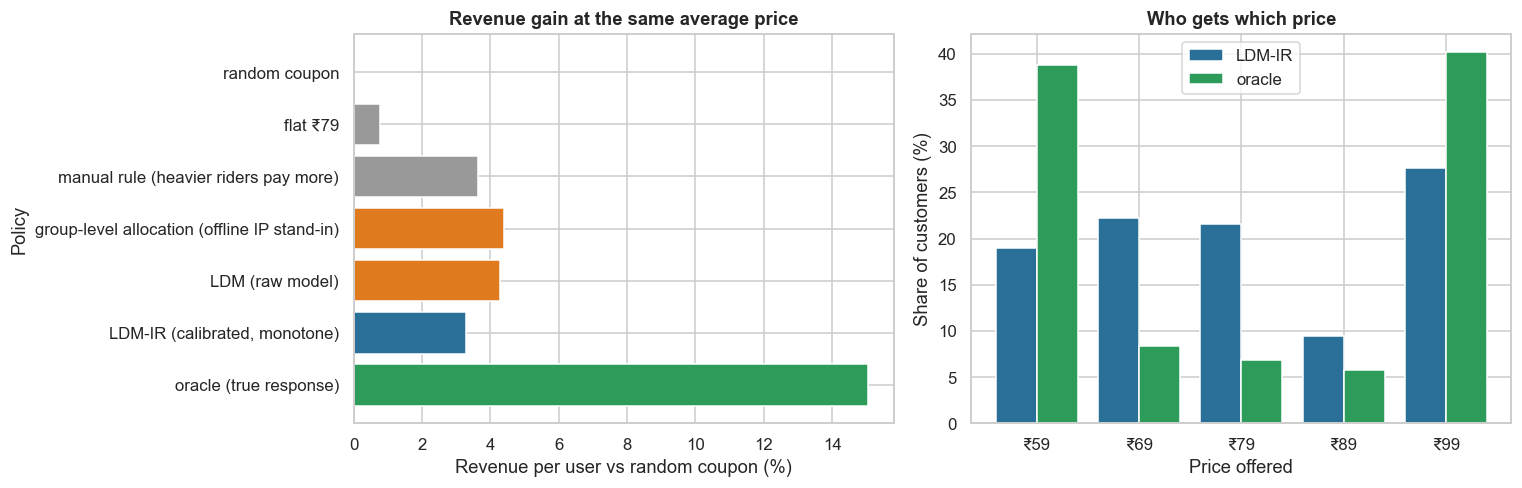

In [12]:
ar = np.arange(N_ON)
def score(j): return dict(rev=TREV[ar, j], cvr=TCV[ar, j], price=LAD[j])
J = {}
J["1 random coupon"] = None
rk = (pd.Series(on.rides_last30.values + (on.user_id.values % 1000) / 1000.0).rank(pct=True).values); J["3 manual rule (heavier riders pay more)"] = np.minimum(4, (rk * 5).astype(int))
J["2 flat ₹79"] = np.full(N_ON, 2); J["4 group-level allocation (offline IP stand-in)"] = jg[on_g]
J["5 LDM (raw model)"] = allocate(RRAW)[1]; J["6 LDM-IR (calibrated, monotone)"] = ju; lam_o, j_o = allocate(TREV); J["7 oracle (true response)"] = j_o
PER = {}; PER["1 random coupon"] = dict(rev=TREV.mean(1), cvr=TCV.mean(1), price=np.full(N_ON, LAD.mean()))
for k, j in J.items():
    if j is not None: PER[k] = score(j)
PER = dict(sorted(PER.items())); R0 = PER["1 random coupon"]["rev"]; RO = PER["7 oracle (true response)"]["rev"]
def boot_ci(d, B=500):
    bs = [d[i].mean() for i in (RNG.integers(0, len(d), len(d)) for _ in range(B))]; return np.percentile(bs, [2.5, 97.5])
rows = []
for k, v in PER.items():
    d = v["rev"] - R0; lo, hi = boot_ci(d) if k != "1 random coupon" else (0, 0)
    rows.append((k, v["price"].mean(), v["cvr"].mean() * 100, v["rev"].mean(), v["rev"].mean() / R0.mean() - 1, lo / R0.mean(), hi / R0.mean(), (v["rev"].mean() - R0.mean()) / (RO.mean() - R0.mean())))
pol = pd.DataFrame(rows, columns=["policy", "avg price (₹)", "conversion (%)", "revenue / user (₹)", "gain vs random", "CI low", "CI high", "share of oracle gain"]).set_index("policy"); print("Budget is an average offered price of at least ₹79.\n"); print(pol.round(4).to_string())
star = "6 LDM-IR (calibrated, monotone)"; rows = []
for k in PER:
    if k == star: continue
    d = PER[star]["rev"] - PER[k]["rev"]; lo, hi = boot_ci(d); tt = stats.ttest_rel(PER[star]["rev"], PER[k]["rev"]); rows.append((k, d.mean(), lo, hi, tt.pvalue))
pc_ = pd.DataFrame(rows, columns=["vs policy", "Δ revenue/user (₹), LDM-IR − other", "CI low", "CI high", "paired t p"]).set_index("vs policy"); pc_["p_holm"] = multipletests(pc_["paired t p"], method="holm")[1]; pc_["relative"] = pc_.iloc[:, 0] / np.array([PER[k]["rev"].mean() for k in pc_.index])
print(); print(pc_.round(4).to_string())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6)); lab = [k.split(" ", 1)[1] for k in pol.index]; cols = ["#999999", "#999999", "#999999", "#e07a1f", "#e07a1f", "#2a6f97", "#2d9c5a"]
axes[0].barh(lab[::-1], pol["gain vs random"].values[::-1] * 100, color=cols[::-1]); axes[0].set_xlabel("Revenue per user vs random coupon (%)"); axes[0].set_ylabel("Policy"); axes[0].set_title("Revenue gain at the same average price")
sh = pd.DataFrame({"price": LAD[J[star]]}).price.value_counts(normalize=True).reindex(LAD, fill_value=0) * 100; sh2 = pd.Series(LAD[J["7 oracle (true response)"]]).value_counts(normalize=True).reindex(LAD, fill_value=0) * 100
x_ = np.arange(5); axes[1].bar(x_ - 0.2, sh.values, 0.4, label="LDM-IR", color="#2a6f97"); axes[1].bar(x_ + 0.2, sh2.values, 0.4, label="oracle", color="#2d9c5a"); axes[1].set_xticks(x_); axes[1].set_xticklabels([f"₹{int(p)}" for p in LAD]); axes[1].set_xlabel("Price offered"); axes[1].set_ylabel("Share of customers (%)"); axes[1].set_title("Who gets which price"); axes[1].legend()
plt.tight_layout(); plt.show()

**Takeaway:** at about the same average price (₹79), **every personalised policy beats random and flat pricing, and the oracle is far ahead**. Revenue per user: random ₹9.84, flat ₹79 ₹9.92, manual rule ₹10.20, group-level ₹10.27, LDM (raw) ₹10.26, **LDM-IR ₹10.17**, oracle ₹11.32. The gain over random is **+3.3% (₹0.32, CI 0.32 to 0.33)** for LDM-IR, and the share of the oracle gain captured is **22%**, against 29% for group-level and 28% for raw LDM. **The paired tests show LDM-IR is significantly behind** the group-level policy (-₹0.108, CI -0.115 to -0.099), the raw LDM (-₹0.097) and the manual rule (-₹0.034, CI -0.042 to -0.025), all Holm p < 0.001. Hypothesis H4 is therefore **rejected in the wrong direction**: the new method does not beat the incumbent here. The calibration step cost revenue (raw LDM is ₹0.097 higher); a plausible reason is that pooled isotonic smoothing flattens differences between prices that the optimiser uses, though we did not test this. LDM-IR's average price is also ₹79.46, slightly above the budget, which works against it.

#### Who gets the discount? (profile of the LDM-IR allocation)

In [13]:
prof = on.assign(price=LAD[J[star]], beta=on["_beta"], rev=PER[star]["rev"]).groupby("price").agg(customers=("price", "size"), rides_30d=("rides_last30", "mean"), prev_sub=("prev_subscriber", "mean"), coupons_90d=("coupons_redeemed_90d", "mean"), true_sensitivity=("beta", "median"))
print(prof.round(3).to_string()); print(f"\nSpearman(true price sensitivity, price offered by LDM-IR) = {stats.spearmanr(on['_beta'], LAD[J[star]])[0]:+.3f}; with the oracle {stats.spearmanr(on['_beta'], LAD[j_o])[0]:+.3f}")

         customers  rides_30d  prev_sub  coupons_90d  true_sensitivity
price                                                                 
59.0000      45682     3.3030    0.1690       1.2380            0.2410
69.0000      53337     4.3940    0.3080       1.0090            0.2120
79.0000      51786     7.0440    0.4350       0.8390            0.1710
89.0000      22765     6.6500    0.6540       0.5900            0.1720
99.0000      66430     5.2880    0.3100       0.7160            0.1990



Spearman(true price sensitivity, price offered by LDM-IR) = -0.120; with the oracle -0.878


**Observation:** LDM-IR gives **₹99 to 66,430 customers and ₹89 to only 22,765**, and its choices barely follow true price sensitivity: the Spearman correlation between true sensitivity and the price offered is **-0.120**, against **-0.878 for the oracle**. Lighter riders (3.3 rides in 30 days, 17% previous subscribers) get ₹59, while ₹79 and ₹89 go to heavier riders (7.0 and 6.7 rides). So the model finds some structure but misses most of the heterogeneity, which explains the small captured share.

### 7.5 A simulated online A/B test and its power

**(a) Why?** The twin gives exact expected values; a real test gives only **noisy outcomes** from a finite sample (Meituan used 3.87 million users). We simulate a **three-arm randomised test**, 80,000 customers per arm (random coupon, group-level incumbent, LDM-IR), drawing each customer's purchase as a **Bernoulli** outcome at the assigned price. Then we ask how often a test of a given size would detect the LDM-IR gain.
- **H5:** H0: revenue per exposed user is equal between LDM-IR and the incumbent. **Welch t-test** and a **two-proportion z-test** for conversion; **Holm** over the three comparisons.
- **Power study:** repeat the whole test 200 times at 10,000, 20,000, 40,000 and 80,000 customers per arm; power = share of runs with p < 0.05.

#### Code

                         users  avg price (₹)  conversion (%)  revenue / user (₹)   s.e.
arm                                                                                     
A random coupon          80000        79.0040         13.1012              9.9137 0.0920
B group-level incumbent  80000        79.6780         12.8688             10.3112 0.0965
C LDM-IR                 80000        79.4396         13.0188             10.1088 0.0940



            Δ revenue/user (₹)  CI low  CI high  relative  Welch p (revenue)  z-test p (conversion)  Holm p (revenue)
comparison                                                                                                           
C vs A                  0.1951 -0.0627   0.4528    0.0197             0.1380                 0.6244            0.2659
C vs B                 -0.2024 -0.4664   0.0616   -0.0196             0.1329                 0.3715            0.2659
B vs A                  0.3975  0.1361   0.6588    0.0401             0.0029                 0.1666            0.0086

True gain of LDM-IR over the incumbent (twin): ₹-0.107 per user (-1.05%); revenue per user has s.d. ₹26.9



Customers per arm for 80% power at the true gain (formula): 985,380
                   power (200 runs)
customers per arm                  
10000                        0.0350
20000                        0.1200
40000                        0.1050
80000                        0.1200


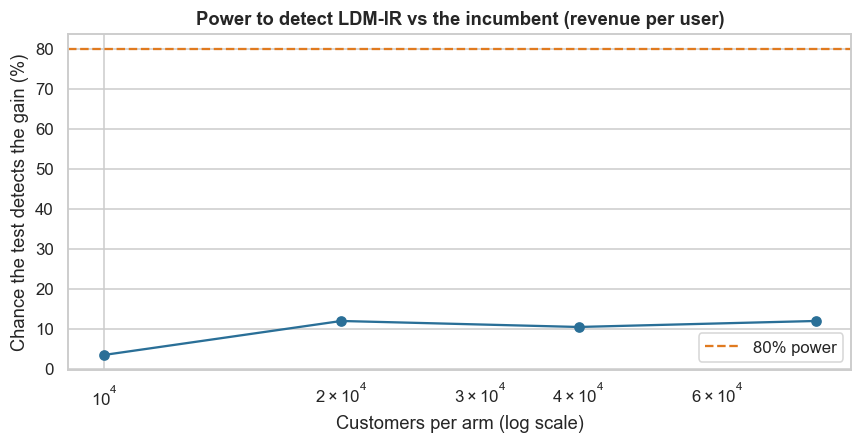

In [14]:
perm = RNG.permutation(N_ON); arms = {"A random coupon": perm[:80000], "B group-level incumbent": perm[80000:160000], "C LDM-IR": perm[160000:]}
pick = {"A random coupon": RNG.integers(0, 5, N_ON), "B group-level incumbent": J["4 group-level allocation (offline IP stand-in)"], "C LDM-IR": J[star]}
OUT = {}
for k, ids in arms.items():
    j = pick[k][ids]; conv = RNG.random(len(ids)) < TCV[ids, j]; OUT[k] = dict(conv=conv.astype(float), rev=conv * LAD[j], price=LAD[j])
rows = []
for k, v in OUT.items(): rows.append((k, len(v["conv"]), v["price"].mean(), v["conv"].mean() * 100, v["rev"].mean(), v["rev"].std(ddof=1) / np.sqrt(len(v["rev"]))))
ab = pd.DataFrame(rows, columns=["arm", "users", "avg price (₹)", "conversion (%)", "revenue / user (₹)", "s.e."]).set_index("arm"); print(ab.round(4).to_string())
rows = []
for a_, b_ in (("C LDM-IR", "A random coupon"), ("C LDM-IR", "B group-level incumbent"), ("B group-level incumbent", "A random coupon")):
    ra, rb = OUT[a_]["rev"], OUT[b_]["rev"]; tw = stats.ttest_ind(ra, rb, equal_var=False); d = ra.mean() - rb.mean(); se = np.sqrt(ra.var(ddof=1) / len(ra) + rb.var(ddof=1) / len(rb))
    ca, cb = OUT[a_]["conv"], OUT[b_]["conv"]; pp_ = (ca.sum() + cb.sum()) / (len(ca) + len(cb)); z = (ca.mean() - cb.mean()) / np.sqrt(pp_ * (1 - pp_) * (1 / len(ca) + 1 / len(cb)))
    rows.append((f"{a_[0]} vs {b_[0]}", d, d - 1.96 * se, d + 1.96 * se, d / rb.mean(), tw.pvalue, 2 * stats.norm.sf(abs(z))))
abt = pd.DataFrame(rows, columns=["comparison", "Δ revenue/user (₹)", "CI low", "CI high", "relative", "Welch p (revenue)", "z-test p (conversion)"]).set_index("comparison"); abt["Holm p (revenue)"] = multipletests(abt["Welch p (revenue)"], method="holm")[1]; print(); print(abt.round(4).to_string())
true_d = (PER[star]["rev"] - PER["4 group-level allocation (offline IP stand-in)"]["rev"]).mean(); sdr = np.concatenate([OUT["C LDM-IR"]["rev"], OUT["B group-level incumbent"]["rev"]]).std()
print(f"\nTrue gain of LDM-IR over the incumbent (twin): ₹{true_d:.3f} per user ({true_d / PER['4 group-level allocation (offline IP stand-in)']['rev'].mean():.2%}); revenue per user has s.d. ₹{sdr:.1f}")
NS = (10000, 20000, 40000, 80000); pw = []
for n_ in NS:
    hit = 0
    for _ in range(200):
        ia, ib = RNG.integers(0, N_ON, n_), RNG.integers(0, N_ON, n_); ja, jb = J[star][ia], J["4 group-level allocation (offline IP stand-in)"][ib]
        ra = (RNG.random(n_) < TCV[ia, ja]) * LAD[ja]; rb = (RNG.random(n_) < TCV[ib, jb]) * LAD[jb]; hit += stats.ttest_ind(ra, rb, equal_var=False).pvalue < 0.05
    pw.append(hit / 200)
need = int(np.ceil(2 * (1.96 + 0.84) ** 2 * sdr ** 2 / true_d ** 2)); pws = pd.DataFrame({"customers per arm": NS, "power (200 runs)": pw}).set_index("customers per arm")
print(f"\nCustomers per arm for 80% power at the true gain (formula): {need:,}"); print(pws.round(3).to_string())
fig, ax = plt.subplots(figsize=(8, 4.2)); ax.plot(NS, np.array(pw) * 100, marker="o", color="#2a6f97"); ax.axhline(80, color="#e07a1f", ls="--", label="80% power"); ax.set_xscale("log"); ax.set_xlabel("Customers per arm (log scale)"); ax.set_ylabel("Chance the test detects the gain (%)"); ax.set_title("Power to detect LDM-IR vs the incumbent (revenue per user)"); ax.legend()
plt.tight_layout(); plt.show()

**Takeaway:** in a realistic three-arm test with **80,000 customers per arm**, LDM-IR earned ₹10.11 per user against ₹10.31 for the incumbent: a difference of **-₹0.20 (CI -₹0.47 to +₹0.06, Welch p = 0.133, Holm p = 0.27)**, which is not significant, although the true gap in the twin is -₹0.107. The incumbent beats random by ₹0.40 (CI 0.14 to 0.66, Holm p = 0.009); LDM-IR vs random (+₹0.20) is not significant (Holm p = 0.27). Conversion differences are not significant. Revenue per user has a standard deviation of ₹26.9, so detecting the true gap with 80% power needs about **985,000 customers per arm**. Simulated power at 10,000 to 80,000 per arm is only **3.5% to 12%** (the non-monotone pattern is simulation noise from 200 runs). Meituan used 3.87 million users, which is the scale needed. A test of ordinary size cannot settle a 1% question.

### 7.6 Staying on budget during the day: PID control of λ

**(a) Why?** The offline λ is set on **planned** traffic. On a day when customers differ (a holiday with more occasional riders), the same λ gives a different average price, so the **budget is missed**. Meituan adds a **PID controller** that adjusts λ as the day unfolds. We simulate a day of **60,000 customers** drawn with a **tilt towards low-engagement riders** (unexpected traffic), arriving in 96 fifteen-minute ticks in hour order.
- λ₀ is trisected on the **planned** traffic (the random-traffic test set, calibrated predictions).
- Static policy: keep λ₀ all day. PID policy: λ_t = max(0, λ₀ + 0.5·e + 0.05·Σe + 0.1·Δe), where e = (budget − average price so far) ÷ budget. The gains are fixed defaults, not tuned.
- **Test:** the day's final average price and the maximum tick-level deviation of the cumulative average from budget; **bootstrap over 200 random days** gives the mean and 95% range of the final error for each policy.

#### Code

Planned lambda0 (random-traffic test set): 0.0383


                                    static lambda     PID
final avg price, one day (₹)              77.8080 78.9950
final error vs budget (%)                 -1.5080 -0.0060
max |deviation| across ticks (₹)           1.4480  0.8480
mean final avg price, 200 days (₹)        77.8260 78.9970
2.5th pct, 200 days (₹)                   77.7100 78.9750
97.5th pct, 200 days (₹)                  77.9230 79.0280
Share of 200 days ending below the ₹79 budget (budget overspend): static 100% | PID 0%  (below by more than ₹0.50)


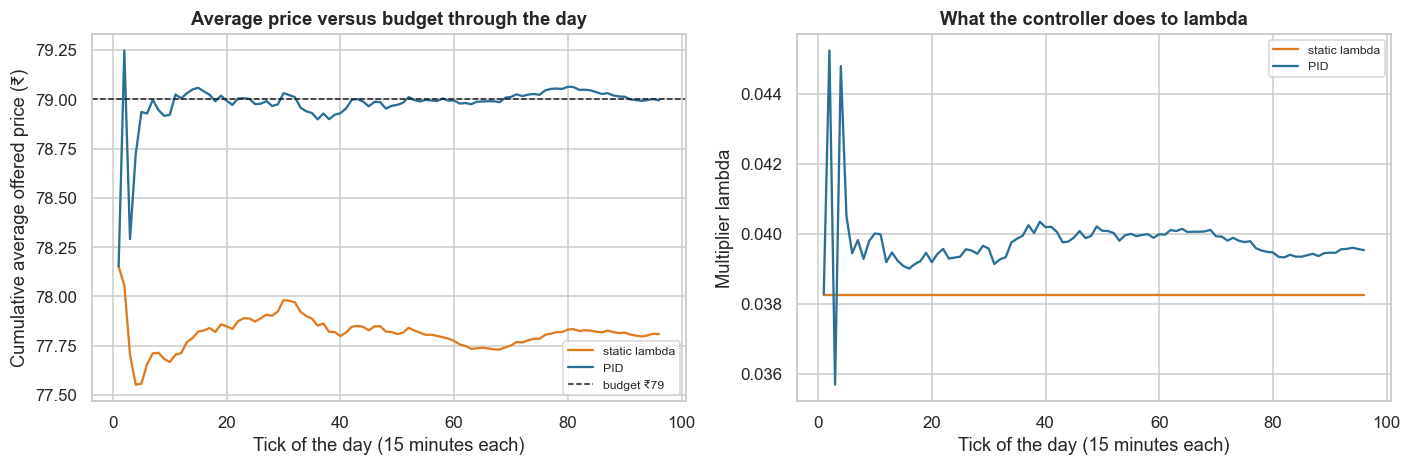

In [15]:
Rte = Pte_cal * LAD[None, :]; lam0 = trisect(Rte); print(f"Planned lambda0 (random-traffic test set): {lam0:.4f}")
zeng = (on.rides_last30.values - on.rides_last30.mean()) / on.rides_last30.std(); wday = np.exp(-0.7 * zeng); wday /= wday.sum()
def simulate_day(rng, n_day=60000, pid=True, ticks=96, kp=0.5, ki=0.05, kd=0.1):
    ids = np.argpartition(-(np.log(wday) + rng.gumbel(size=N_ON)), n_day)[:n_day]; ids = ids[np.lexsort((rng.random(n_day), on.arrival_hour.values[ids]))]; chunks = np.array_split(ids, ticks)
    lam, S, n_, e_sum, e_prev = lam0, 0.0, 0, 0.0, 0.0; traj = []; lams = []
    for ch in chunks:
        if pid and n_ > 0:
            e = (BUDGET - S / n_) / BUDGET; e_sum += e; lam = max(0.0, lam0 + kp * e + ki * e_sum + kd * (e - e_prev)); e_prev = e
        j = (RCAL[ch] + lam * LAD[None, :]).argmax(1); S += LAD[j].sum(); n_ += len(ch); traj.append(S / n_); lams.append(lam)
    return np.array(traj), np.array(lams)
tj_s, lm_s = simulate_day(np.random.default_rng(1), pid=False); tj_p, lm_p = simulate_day(np.random.default_rng(1), pid=True)
fin_s, fin_p = [], []
for s_ in range(200):
    a_, _ = simulate_day(np.random.default_rng(1000 + s_), pid=False); b_, _ = simulate_day(np.random.default_rng(1000 + s_), pid=True); fin_s.append(a_[-1]); fin_p.append(b_[-1])
fin_s, fin_p = np.array(fin_s), np.array(fin_p)
res_pid = pd.DataFrame({"static lambda": [tj_s[-1], (tj_s[-1] - BUDGET) / BUDGET * 100, np.abs(tj_s - BUDGET).max(), fin_s.mean(), *np.percentile(fin_s, [2.5, 97.5])], "PID": [tj_p[-1], (tj_p[-1] - BUDGET) / BUDGET * 100, np.abs(tj_p - BUDGET).max(), fin_p.mean(), *np.percentile(fin_p, [2.5, 97.5])]},
                       index=["final avg price, one day (₹)", "final error vs budget (%)", "max |deviation| across ticks (₹)", "mean final avg price, 200 days (₹)", "2.5th pct, 200 days (₹)", "97.5th pct, 200 days (₹)"]); print(res_pid.round(3).to_string())
print(f"Share of 200 days ending below the ₹79 budget (budget overspend): static {np.mean(fin_s < BUDGET - 0.5):.0%} | PID {np.mean(fin_p < BUDGET - 0.5):.0%}  (below by more than ₹0.50)")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4)); tk = np.arange(1, 97)
axes[0].plot(tk, tj_s, label="static lambda", color="#e07a1f"); axes[0].plot(tk, tj_p, label="PID", color="#2a6f97"); axes[0].axhline(BUDGET, color="k", ls="--", lw=1, label="budget ₹79"); axes[0].set_xlabel("Tick of the day (15 minutes each)"); axes[0].set_ylabel("Cumulative average offered price (₹)"); axes[0].set_title("Average price versus budget through the day"); axes[0].legend(fontsize=8)
axes[1].plot(tk, lm_s, label="static lambda", color="#e07a1f"); axes[1].plot(tk, lm_p, label="PID", color="#2a6f97"); axes[1].set_xlabel("Tick of the day (15 minutes each)"); axes[1].set_ylabel("Multiplier lambda"); axes[1].set_title("What the controller does to lambda"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Takeaway:** a fixed lambda planned from the test set (0.0383) **drifts below the budget**: the one-day average price ended at **₹77.81 (1.5% below budget)**, and across 200 simulated days the mean final price was ₹77.83 (2.5th to 97.5th percentile 77.71 to 77.92), so **100% of days ended more than ₹0.50 below the ₹79 budget**, meaning the discount budget was overspent every day. The **PID controller ended at ₹78.995 (error -0.006%)**; across 200 days the mean was ₹78.997 (78.975 to 79.028) and 0% of days ended below budget. The maximum deviation during the day fell from ₹1.45 to ₹0.85. Meituan reports about 3% overshoot without control and about 1% with it; ours is 1.5% without, because our simulated traffic shift is different. The direction and the benefit match.

### 7.7 Why random traffic? Training on confounded logs

**(a) Why?** In production, coupons are never random: a targeting rule decides. If we train the conversion model on those logs, price is **correlated with propensity** (here, high-propensity users were offered **higher** prices), so the model confuses "buys anyway" with "insensitive to price". We train the same pipeline on **80,000 logged-policy users** and on **80,000 random-traffic users** (same size), build LDM-IR from each, and score both in the twin.
- **H6:** H0: policy value is equal. **Paired bootstrap** of the per-user revenue difference. We also report how well each model recovers the **sign** of the price effect (share of customers whose predicted conversion falls with price) and the Spearman correlation between the model's predicted price sensitivity and the hidden truth.

#### Code

In [16]:
lg_ = parts["logged"]; lg_ = lg_[lg_.offered_price.isin(LAD)].reset_index(drop=True); sub_r = tr.iloc[:80000]; cut = int(0.75 * len(lg_)); m_log, iso_log = fit_cvr(lg_.iloc[:cut], lg_.iloc[cut:]); cut2 = int(0.75 * len(sub_r)); m_rnd, iso_rnd = fit_cvr(sub_r.iloc[:cut2], sub_r.iloc[cut2:])
def sens_of(P): return np.log(np.maximum(P[:, 0], 1e-6)) - np.log(np.maximum(P[:, -1], 1e-6))   # predicted log-conversion drop from ₹99 to ₹59 (higher = more price sensitive)
rows = []; PX = {}
for name, m_, iso_ in (("trained on logged targeted policy", m_log, iso_log), ("trained on random traffic (same size)", m_rnd, iso_rnd)):
    Pc = calibrated_ladder(m_, iso_, on); jj = allocate(Pc * LAD[None, :])[1]; rv = TREV[ar, jj]; PX[name] = rv; Pr = ladder_pred(m_, on)
    rows.append((name, LAD[jj].mean(), rv.mean(), rv.mean() / R0.mean() - 1, (rv.mean() - R0.mean()) / (RO.mean() - R0.mean()), (np.diff(Pr, axis=1) < 0).all(1).mean(), (Pr[:, 0] > Pr[:, -1]).mean(), stats.spearmanr(sens_of(Pr), np.log(on["_beta"]))[0]))
cf = pd.DataFrame(rows, columns=["training data", "avg price (₹)", "revenue / user (₹)", "gain vs random", "share of oracle gain", "raw curves strictly falling in price", "raw: conversion at ₹59 > at ₹99", "Spearman(pred. sensitivity, true β)"]).set_index("training data")
a_, b_ = PX["trained on random traffic (same size)"], PX["trained on logged targeted policy"]; d = a_ - b_; lo, hi = boot_ci(d); print(cf.round(4).T.to_string()); print(f"\nRandom-traffic model minus logged-policy model: ₹{d.mean():.3f} per user (95% CI {lo:.3f} to {hi:.3f}); paired t p = {stats.ttest_rel(a_, b_).pvalue:.2g}")

training data                         trained on logged targeted policy  trained on random traffic (same size)
avg price (₹)                                                   99.0000                                79.1828
revenue / user (₹)                                               9.0165                                10.1282
gain vs random                                                  -0.0839                                 0.0291
share of oracle gain                                            -0.5574                                 0.1930
raw curves strictly falling in price                             0.0000                                 0.9088
raw: conversion at ₹59 > at ₹99                                  0.0000                                 0.9999
Spearman(pred. sensitivity, true β)                              0.2573                                 0.2577

Random-traffic model minus logged-policy model: ₹1.112 per user (95% CI 1.101 to 1.123); paired t p = 0


**Observation:** training on confounded logs is a **real failure**. The model trained on the logged targeting policy learned that customers offered a high price convert more, so none of its curves is strictly falling in price (0%), and the optimiser sent **everyone to ₹99**, earning **₹9.02 per user, 8.4% below random**. The same model trained on random traffic of the same size earned **₹10.13 (+2.9% over random, 19% of the oracle gain)**, with 91% of curves strictly falling and the ₹59 prediction above the ₹99 prediction for 99.99% of customers. The difference is **₹1.11 per user (CI 1.10 to 1.12)**. Both models rank customers by price sensitivity about equally poorly (Spearman 0.257 and 0.258), so the problem is the level and sign of the price effect, not the ranking. This is the case for keeping a random-traffic slice. H6 is rejected.

## 8. ML Section — what we built and what is beyond it

- **A single S-learner:** price is a feature of one gradient-boosting classifier, scored at every ladder price. It is easy to serve, but it only learns who reacts to price **if the random-traffic data has enough signal per price level** (we saw in 7.1 and 7.7 how much depends on the data design).
- **Calibration is part of the model:** the optimiser consumes probabilities, so isotonic regression (a monotone mapping from predicted to observed conversion) and the non-increasing-in-price step are part of the pipeline, not decoration.
- **Alternatives:** monotonic constraints on price inside the model, or separate models per price (T-learner), or **uplift forests** that model the incremental effect of the coupon directly. Indian practice leans towards uplift. We did not tune any model (fixed defaults, per the brief).
- **Beyond this notebook:** contextual bandits to keep exploring, budget pacing across cities, and fairness checks on price discrimination.

## 9. Business Translation — ₹ impact

Assumptions (D-22-07): **2 crore customers are exposed each month**, revenue is the monthly subscription price paid by customers who convert, and variable cost is 10% of price (so incremental contribution = 90% of incremental revenue). We compare **LDM-IR with the incumbent group-level allocation** and, for context, with random coupons. Scenarios: **worst** = lower end of the bootstrap CI × 50% (model decay, twin optimism); **base** = point estimate × 70%; **best** = point estimate × 100%.

#### Code

In [17]:
EXP, VC = 2e7, 0.10; inc = "4 group-level allocation (offline IP stand-in)"; rows = []
for lab_, ref in (("vs incumbent group-level", inc), ("vs random coupon", "1 random coupon")):
    d = PER[star]["rev"] - PER[ref]["rev"]; lo, hi = boot_ci(d); pt = d.mean()
    for sc_n, val in (("worst (CI low × 50%)", lo * 0.5), ("base (point × 70%)", pt * 0.7), ("best (point × 100%)", pt)):
        rows.append((lab_, sc_n, val, val * EXP * (1 - VC) / 1e7, val * EXP * (1 - VC) * 12 / 1e7))
money = pd.DataFrame(rows, columns=["comparison", "scenario", "Δ revenue per exposed user (₹)", "₹ crore / month (contribution)", "₹ crore / year (contribution)"]).set_index(["comparison", "scenario"]); money.round(3)

Δ revenue per exposed user (₹)  ₹ crore / month (contribution)  ₹ crore / year (contribution)
comparison               scenario                                                                                                           
vs incumbent group-level worst (CI low × 50%)                         -0.0580                         -0.1040                        -1.2490
                         base (point × 70%)                           -0.0750                         -0.1350                        -1.6250
                         best (point × 100%)                          -0.1070                         -0.1930                        -2.3210
vs random coupon         worst (CI low × 50%)                          0.1580                          0.2850                         3.4220
                         base (point × 70%)                            0.2270                          0.4080                         4.9010
                         best (point × 100%)                           0.3240                          0.5840                         7.0020

**Takeaway (business reading):** against **random coupons**, LDM-IR is worth about **₹4.9 crore a year** in contribution (base: point estimate × 70%), with a range of **₹3.4 crore (worst) to ₹7.0 crore (best)**, or about ₹0.41 crore a month in the base case. Against the **incumbent group-level allocation** the value is **negative**: base **-₹1.6 crore a year**, range -₹1.2 to -₹2.3 crore. The "worst" scenario for this comparison looks less negative because the 50% haircut is applied to a negative number, so read the whole range as a loss. The assumptions (2 crore exposed users a month, 10% variable cost) are ours. The business case supports personalisation in general, not this model over the incumbent.

## 10. Recommendation and Decision

**Recommendation**

1. **Do not replace the incumbent group-level allocation with LDM-IR on this evidence.** In the twin it earns ₹0.11 per exposed user less (CI -0.115 to -0.099), about **-₹1.6 crore a year** in the base case. Personalisation itself is worth about ₹4.9 crore a year over random coupons.
2. **Adopt the PID budget controller now.** A fixed multiplier left the average price 1.5% below budget on all 200 simulated days; PID held it within 0.01%.
3. **Keep a 20% random-traffic slice.** Training on confounded logs lost 8.4% against random and sent every customer to ₹99.
4. **Improve the model before testing again:** price-monotone constraints inside the model, uplift forests, and a look at why isotonic calibration lowered revenue (raw LDM ₹0.097 per user higher).
5. **Run a properly sized A/B test**, roughly **1 million customers per arm** for a 1% gap, or test a larger expected gain. A test with 80,000 per arm has only about a 12% chance of detecting the current gap.

**Decision rule.** Roll out a new allocator only if its paired twin gain over the incumbent is positive with the CI above zero, and a live test confirms it.

**KPIs.** Revenue per exposed user at equal average price; average price versus the ₹79 budget (target within 1%); PCOC between 0.97 and 1.03 by price; share of customers with non-monotone curves (target 0%); share of traffic in the random slice (20%).

## 11. Risks, Limitations and Next Steps

- **Simulated response:** the true price response, the ladder and the budget are our assumptions. The gain of personalisation depends on how much price sensitivity varies between customers in reality; the Meituan result (2.8% in one city) is much smaller than our oracle ceiling.
- **The twin favours the model:** the truth is smooth and the features explain part of the sensitivity by construction. Real data has more noise, so treat our percentages as upper-end.
- **Revenue is not profit:** we ignore cannibalisation of full-price buyers over time, churn, and the long-term effect of discounts on reference prices.
- **Fairness and regulation:** showing different prices to different people is sensitive. Review rules on discrimination, transparency and consumer protection before launch.
- **Feedback loops:** once the model sets the prices, new logs are confounded again. Keep a random-traffic slice (Meituan used 20%) for retraining and calibration monitoring.
- **Next steps:** run the real random-traffic experiment, train an uplift or monotone model, A/B test against the incumbent at the sample size from 7.5, and wire up the controller with alerts.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Revenue per exposed user | price × P(convert at that price) |
| Allocation problem | max Σᵢ Σⱼ pⱼ·cᵢⱼ·xᵢⱼ  subject to  Σⱼ xᵢⱼ = 1 and (1/N) Σᵢ Σⱼ pⱼ·xᵢⱼ ≥ budget |
| Lagrangian choice | for customer i choose j maximising pⱼ·cᵢⱼ + λ·pⱼ, λ ≥ 0 |
| Dual function | g(λ) = Σᵢ maxⱼ(pⱼ·cᵢⱼ + λ·pⱼ) − λ·N·budget (convex in λ) |
| PCOC | Σ predicted ÷ Σ observed conversions |
| Calibration slope | slope of the logistic regression of outcome on the model log-odds |
| ECE | Σ over bins (share) × |mean predicted − mean observed| |
| PID update | λₜ = max(0, λ₀ + Kp·e + Ki·Σe + Kd·Δe) |
| Sample size per arm | 2·(1.96 + 0.84)²·σ² ÷ Δ² |

| Term | Meaning |
|---|---|
| CVR | Conversion rate: share of exposed customers who subscribe |
| Predict-then-optimise | Predict outcomes first, then choose actions with an optimiser |
| Lagrangian relaxation | Moving a hard budget limit into the objective with a price (λ) |
| Trisection | Search for the minimum of a convex function by splitting the range in three |
| Isotonic regression | Fitting a monotone step function |
| Uplift model | A model of the extra effect of a treatment (coupon) on each customer |
| Oracle | A policy that knows the true response; the ceiling |
| Digital twin | A simulation in which the true behaviour is known |
| PID controller | Feedback controller using present, accumulated and changing error |